In [42]:
import  numpy as np
import  matplotlib.pyplot as plt
from    scipy.integrate import solve_ivp

In [43]:
EVENTS = np.array([
    [+1,  0,  0],   # birth
    [-1, +1,  0],   # infection
    [ 0, -1, +1],   # recovery
    [-1,  0,  0],   # S dies
    [ 0, -1,  0],   # I dies
    [ 0,  0, -1],   # R dies
])

In [44]:
def get_rates(state, params):

    S, I, R = state
    beta = params["beta"]
    gamma = params["gamma"]
    mu = params["mu"]
    N0 = params["N0"]
    N = S + I + R

    return np.array([
        mu * N0,                              # birth
        beta * S * I / N if N > 0 else 0.0,   # infection
        gamma * I,                            # recovery
        mu * S,                               # S dies
        mu * I,                               # I dies
        mu * R,                               # R dies
    ])

In [45]:
def first_reaction_step(rates, rng):

    taus = np.full(len(rates), np.inf)
    mask = rates > 0
    taus[mask] = rng.exponential(1.0 / rates[mask])
    event = np.argmin(taus)

    return taus[event], event

In [46]:
def gillespie(state0, params, t_max, seed=None):

    rng = np.random.default_rng(seed)
    t, state = 0.0, np.array(state0, dtype=int)
    times, states = [t], [state.copy()]

    while t < t_max:
        rates = get_rates(state, params)
        if rates.sum() == 0:
            break
        tau, event = first_reaction_step(rates, rng)
        t += tau
        state = state + EVENTS[event]
        times.append(t)
        states.append(state.copy())

    return np.array(times), np.array(states)

In [47]:
def ode_rhs(t, state, params):

    rates = get_rates(state, params)

    return np.dot(EVENTS.T, rates)


def deterministic(state0, params, t_max, n_points=1000):

    t_eval = np.linspace(0, t_max, n_points)
    sol = solve_ivp(
        ode_rhs, (0, t_max), state0, args=(params,), t_eval=t_eval
    )

    return sol.t, sol.y.T

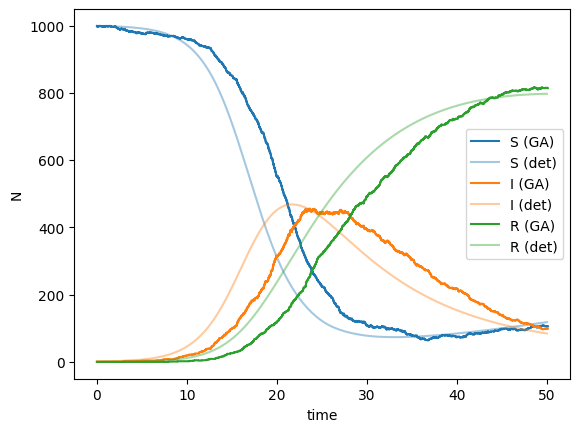

In [55]:
# Zoomed in so the delayed transients are more apparent.

params = {"beta": 0.5, "gamma": 0.1, "mu": 0.01, "N0": 1000}
times, states = gillespie([999, 1, 0], params, t_max=50, seed=1)

params = {"beta": 0.5, "gamma": 0.1, "mu": 0.01, "N0": 1000}
times_ode, states_ode = deterministic([999, 1, 0], params, t_max=50)

plt.step(times,     states[:, 0], where="post", color="tab:blue",   label="S (GA)")
plt.plot(times_ode, states_ode[:, 0], color="tab:blue",   alpha=0.4, label="S (det)")
plt.step(times,     states[:, 1], where="post", color="tab:orange", label="I (GA)")
plt.plot(times_ode, states_ode[:, 1], color="tab:orange", alpha=0.4, label="I (det)")
plt.step(times,     states[:, 2], where="post", color="tab:green",  label="R (GA)")
plt.plot(times_ode, states_ode[:, 2], color="tab:green",  alpha=0.4, label="R (det)")

plt.xlabel("time"); plt.ylabel("N"); plt.legend()
plt.show()

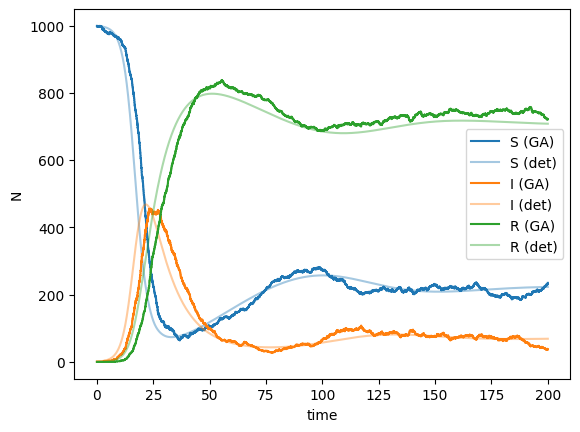

In [54]:
# Zoomed out so the stochastic deviations from the deterministic model are more apparent.

params = {"beta": 0.5, "gamma": 0.1, "mu": 0.01, "N0": 1000}
times, states = gillespie([999, 1, 0], params, t_max=200, seed=1)

params = {"beta": 0.5, "gamma": 0.1, "mu": 0.01, "N0": 1000}
times_ode, states_ode = deterministic([999, 1, 0], params, t_max=200)

plt.step(times,     states[:, 0], where="post", color="tab:blue",   label="S (GA)")
plt.plot(times_ode, states_ode[:, 0], color="tab:blue",   alpha=0.4, label="S (det)")
plt.step(times,     states[:, 1], where="post", color="tab:orange", label="I (GA)")
plt.plot(times_ode, states_ode[:, 1], color="tab:orange", alpha=0.4, label="I (det)")
plt.step(times,     states[:, 2], where="post", color="tab:green",  label="R (GA)")
plt.plot(times_ode, states_ode[:, 2], color="tab:green",  alpha=0.4, label="R (det)")

plt.xlabel("time"); plt.ylabel("N"); plt.legend()
plt.show()